# Movies Dataset — Data Cleaning, Exploration & Analysis

**Assignment:** Data Cleaning, Exploratory Data Analysis (EDA), and Insights  
**Dataset:** `JYFylt.csv`  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## 1. Objective
This project inspects a movie dataset, checks data quality, prepares analysis-friendly columns, explores its distributions, and presents findings supported by tables and charts.

> The dataset contains movie metadata. Results below describe this supplied file only; they should not be interpreted as rankings of all movies ever made.

## 2. Import libraries and load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

from pathlib import Path
DATA_PATH = Path("JYFylt.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/movies_dataset_assignment/JYFylt.csv")
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.head())

Dataset loaded successfully.
Rows: 1629 | Columns: 18


,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
0,Uri: The Surgical Strike,tt8291224,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Uri:_The_Surgica...,Uri: The Surgical Strike,Uri: The Surgical Strike,0,2019,138,Action|Drama|War,8.4,35112,Divided over five chapters the film chronicle...,Indian army special forces execute a covert op...,NaN,Vicky Kaushal|Paresh Rawal|Mohit Raina|Yami Ga...,4 wins,11 January 2019 (USA)
1,Battalion 609,tt9472208,NaN,https://en.wikipedia.org/wiki/Battalion_609,Battalion 609,Battalion 609,0,2019,131,War,4.1,73,The story revolves around a cricket match betw...,The story of Battalion 609 revolves around a c...,NaN,Vicky Ahuja|Shoaib Ibrahim|Shrikant Kamat|Elen...,NaN,11 January 2019 (India)
2,The Accidental Prime Minister (film),tt6986710,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/The_Accidental_P...,The Accidental Prime Minister,The Accidental Prime Minister,0,2019,112,Biography|Drama,6.1,5549,Based on the memoir by Indian policy analyst S...,Explores Manmohan Singh's tenure as the Prime ...,NaN,Anupam Kher|Akshaye Khanna|Aahana Kumra|Atul S...,NaN,11 January 2019 (USA)
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,0,2019,121,Crime|Drama,6.0,1891,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA)
4,Evening Shadows,tt6028796,NaN,https://en.wikipedia.org/wiki/Evening_Shadows,Evening Shadows,Evening Shadows,0,2018,102,Drama,7.3,280,While gay rights and marriage equality has bee...,Under the 'Evening Shadows' truth often plays...,NaN,Mona Ambegaonkar|Ananth Narayan Mahadevan|Deva...,17 wins & 1 nomination,11 January 2019 (India)


## 3. Initial exploration

In [2]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()

Dataset dimensions: (1629, 18)

Column names:
['title_x', 'imdb_id', 'poster_path', 'wiki_link', 'title_y', 'original_title', 'is_adult', 'year_of_release', 'runtime', 'genres', 'imdb_rating', 'imdb_votes', 'story', 'summary', 'tagline', 'actors', 'wins_nominations', 'release_date']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1629 entries, 0 to 1628
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   title_x           1629 non-null   object 
 1   imdb_id           1629 non-null   object 
 2   poster_path       1526 non-null   object 
 3   wiki_link         1629 non-null   object 
 4   title_y           1629 non-null   object 
 5   original_title    1629 non-null   object 
 6   is_adult          1629 non-null   int64  
 7   year_of_release   1629 non-null   int64  
 8   runtime           1629 non-null   object 
 9   genres            1629 non-null   object 
 10  imdb_ra

In [3]:
print("Descriptive statistics (numeric columns):")
display(df.describe().T)
print("\nNumber of unique values per column:")
display(df.nunique().sort_values(ascending=False).to_frame("unique_values"))

Descriptive statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
is_adult,1629.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
year_of_release,1629.0,2010.263966,5.381542,2001.0,2005.0,2011.0,2015.0,2019.0
imdb_rating,1629.0,5.557459,1.567609,0.0,4.4,5.6,6.8,9.4
imdb_votes,1629.0,5384.263352,14552.103231,0.0,233.0,1000.0,4287.0,310481.0



Number of unique values per column:


,unique_values
wiki_link,1629
title_x,1625
imdb_id,1623
original_title,1621
title_y,1620
actors,1617
summary,1604
story,1603
poster_path,1517
imdb_votes,1267


## 4. Data quality checks

In [4]:
print("Missing values by column:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate IMDb IDs:", df["imdb_id"].duplicated().sum())

Missing values by column:


,missing_count
tagline,1072
wins_nominations,922
release_date,107
poster_path,103
story,20
actors,5


Exact duplicate rows: 0
Duplicate IMDb IDs: 6


In [5]:
# Check special missing-value markers and blank strings.
for col in df.select_dtypes(include="object").columns:
    marker_count = df[col].astype(str).str.strip().eq(r"\\N").sum()
    blank_count = df[col].astype(str).str.strip().eq("").sum()
    if marker_count or blank_count:
        print(f"{col}: '\\N' markers={marker_count}, blank strings={blank_count}")

## 5. Data cleaning

Cleaning decisions:
- Convert whitespace and the source's `\\N` missing-value marker to real missing values.
- Trim leading/trailing whitespace from text fields.
- Convert `runtime` into a numeric `runtime_minutes` column. Unavailable or non-numeric runtimes become missing.
- Convert `is_adult` from 0/1 into a Boolean value.
- Remove exact duplicate rows (if any).
- Keep rows with missing optional metadata rather than deleting useful movie records. Missingness in fields such as tagline and awards is substantial, so blanket row deletion would discard many records.
- Keep the original `runtime` column for traceability.

In [6]:
clean = df.copy()

for col in clean.select_dtypes(include="object").columns:
    clean[col] = clean[col].replace(r"^\\s*\\\\N\\s*$", np.nan, regex=True)
    clean[col] = clean[col].apply(lambda value: value.strip() if isinstance(value, str) else value)

clean["runtime_minutes"] = pd.to_numeric(clean["runtime"], errors="coerce")
clean["is_adult"] = clean["is_adult"].astype(bool)
clean = clean.drop_duplicates().reset_index(drop=True)

print("Original shape:", df.shape)
print("Cleaned shape:", clean.shape)
print("Exact duplicate rows remaining:", clean.duplicated().sum())
display(clean.head())

Original shape: (1629, 18)
Cleaned shape: (1629, 19)
Exact duplicate rows remaining: 0


,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date,runtime_minutes
0,Uri: The Surgical Strike,tt8291224,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Uri:_The_Surgica...,Uri: The Surgical Strike,Uri: The Surgical Strike,False,2019,138,Action|Drama|War,8.4,35112,Divided over five chapters the film chronicle...,Indian army special forces execute a covert op...,NaN,Vicky Kaushal|Paresh Rawal|Mohit Raina|Yami Ga...,4 wins,11 January 2019 (USA),138.0
1,Battalion 609,tt9472208,NaN,https://en.wikipedia.org/wiki/Battalion_609,Battalion 609,Battalion 609,False,2019,131,War,4.1,73,The story revolves around a cricket match betw...,The story of Battalion 609 revolves around a c...,NaN,Vicky Ahuja|Shoaib Ibrahim|Shrikant Kamat|Elen...,NaN,11 January 2019 (India),131.0
2,The Accidental Prime Minister (film),tt6986710,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/The_Accidental_P...,The Accidental Prime Minister,The Accidental Prime Minister,False,2019,112,Biography|Drama,6.1,5549,Based on the memoir by Indian policy analyst S...,Explores Manmohan Singh's tenure as the Prime ...,NaN,Anupam Kher|Akshaye Khanna|Aahana Kumra|Atul S...,NaN,11 January 2019 (USA),112.0
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,False,2019,121,Crime|Drama,6.0,1891,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA),121.0
4,Evening Shadows,tt6028796,NaN,https://en.wikipedia.org/wiki/Evening_Shadows,Evening Shadows,Evening Shadows,False,2018,102,Drama,7.3,280,While gay rights and marriage equality has bee...,Under the 'Evening Shadows' truth often plays...,NaN,Mona Ambegaonkar|Ananth Narayan Mahadevan|Deva...,17 wins & 1 nomination,11 January 2019 (India),102.0


In [7]:
print("Missing values after cleaning:")
display(clean.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Valid numeric runtimes:", clean["runtime_minutes"].notna().sum())

Missing values after cleaning:


,missing_count
tagline,1072
wins_nominations,922
runtime_minutes,119
release_date,107
poster_path,103
story,20
actors,5
imdb_id,0
title_x,0
wiki_link,0


Valid numeric runtimes: 1510


## 6. Exploratory data analysis

### 6.1 Release-year distribution

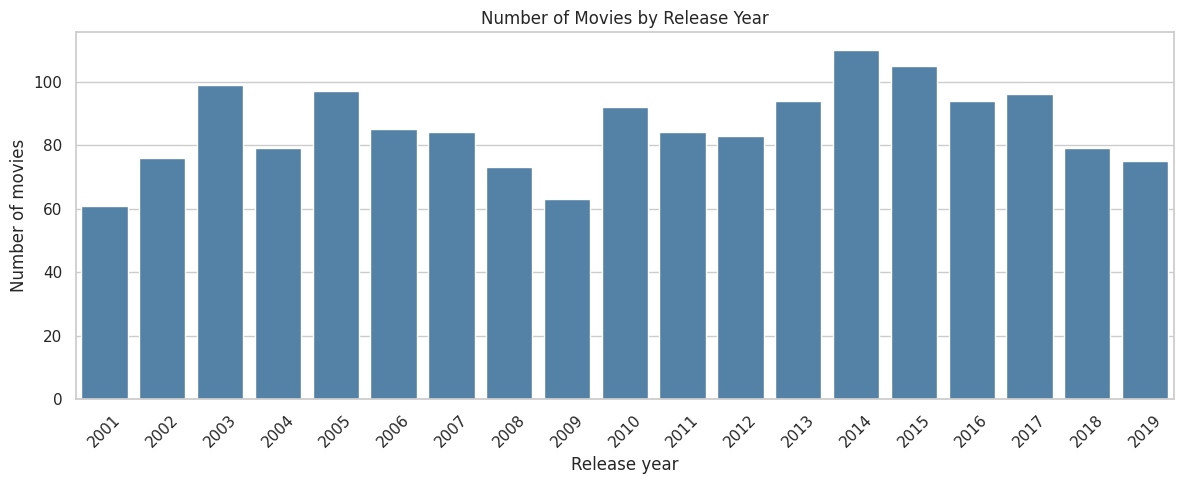

,movie_count
year_of_release,
2001,61
2002,76
2003,99
2004,79
2005,97
2006,85
2007,84
2008,73
2009,63


In [8]:
plt.figure(figsize=(12, 5))
sns.countplot(data=clean, x="year_of_release", order=sorted(clean["year_of_release"].dropna().unique()), color="steelblue")
plt.title("Number of Movies by Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(clean["year_of_release"].value_counts().sort_index().to_frame("movie_count"))

### 6.2 IMDb rating distribution

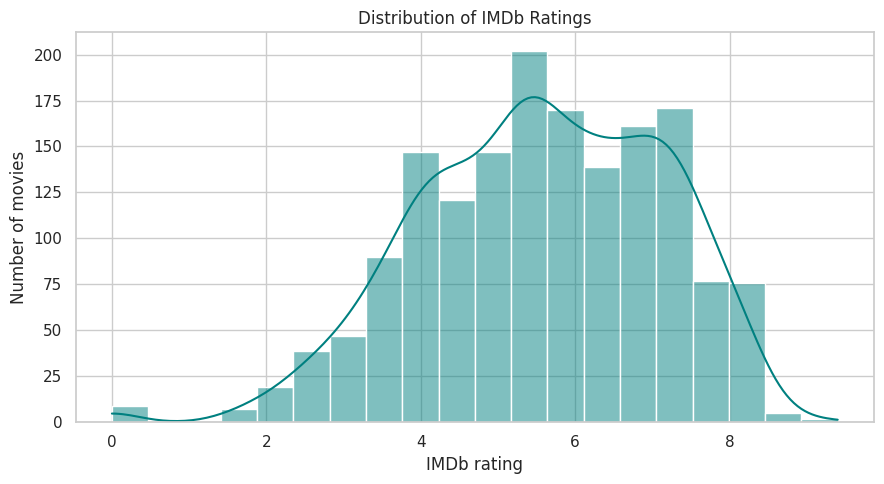

,IMDb rating
count,1629.000000
mean,5.557459
std,1.567609
min,0.000000
25%,4.400000
50%,5.600000
75%,6.800000
max,9.400000


In [9]:
plt.figure(figsize=(9, 5))
sns.histplot(clean["imdb_rating"], bins=20, kde=True, color="teal")
plt.title("Distribution of IMDb Ratings")
plt.xlabel("IMDb rating")
plt.ylabel("Number of movies")
plt.tight_layout()
plt.show()
display(clean["imdb_rating"].describe().to_frame("IMDb rating"))

### 6.3 Runtime distribution

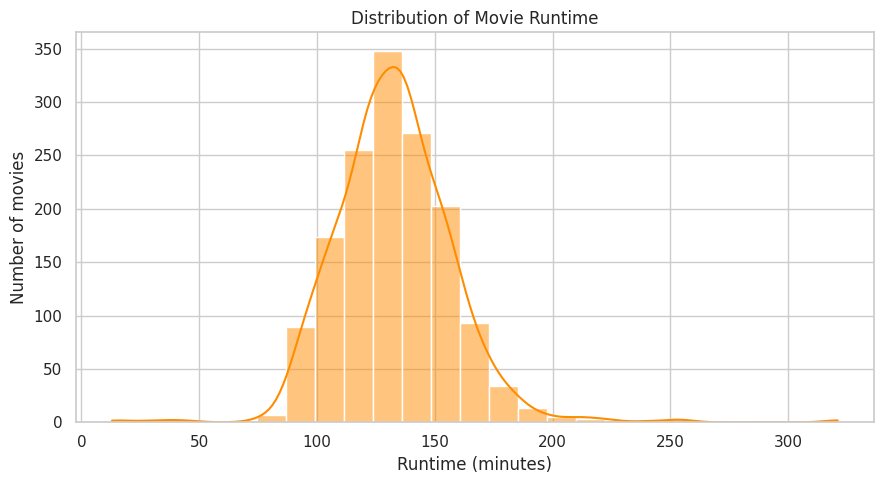

,Runtime in minutes
count,1510.000000
mean,132.854305
std,24.995373
min,13.000000
25%,118.000000
50%,132.000000
75%,147.000000
max,321.000000


In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(clean["runtime_minutes"].dropna(), bins=25, kde=True, color="darkorange")
plt.title("Distribution of Movie Runtime")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of movies")
plt.tight_layout()
plt.show()
display(clean["runtime_minutes"].describe().to_frame("Runtime in minutes"))

### 6.4 Genre exploration

,movie_genre_occurrences
genres,
Drama,1085
Comedy,571
Romance,451
Action,431
Crime,279
Thriller,274
Mystery,107
Musical,88
Family,74


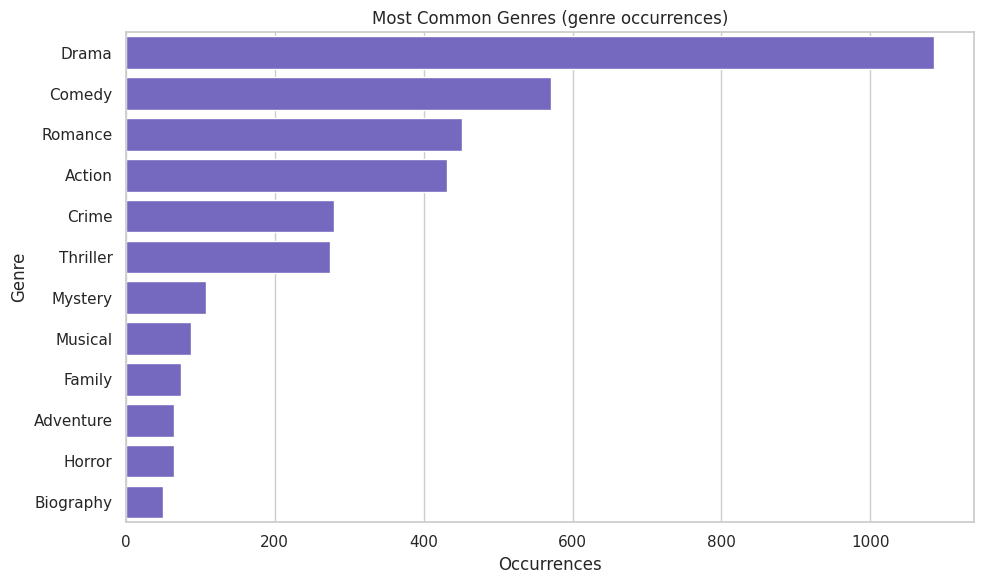

In [11]:
genre_counts = (clean["genres"].dropna()
                .str.split("|").explode().str.strip()
                .value_counts())
display(genre_counts.to_frame("movie_genre_occurrences").head(15))

plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.head(12).values, y=genre_counts.head(12).index, color="slateblue")
plt.title("Most Common Genres (genre occurrences)")
plt.xlabel("Occurrences")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

## 7. Analysis

### 7.1 Highest-rated movies (minimum 1,000 IMDb votes)

In [12]:
# A vote threshold reduces the chance that a very small number of votes dominates the ranking.
top_rated = (clean.loc[clean["imdb_votes"] >= 1000,
                       ["title_x", "year_of_release", "genres", "imdb_rating", "imdb_votes"]]
             .sort_values(["imdb_rating", "imdb_votes"], ascending=[False, False])
             .head(10))
display(top_rated.reset_index(drop=True))

,title_x,year_of_release,genres,imdb_rating,imdb_votes
0,Humsafar,2011,Drama|Romance,9.0,2968
1,Saand Ki Aankh,2019,Biography|Drama,8.9,1902
2,Ghost (2019 film),2019,Horror|Thriller,8.7,1379
3,Sachin: A Billion Dreams,2017,Documentary|Sport,8.6,7239
4,Black Friday (2007 film),2004,Action|Crime|Drama,8.5,16761
5,3 Idiots,2009,Comedy|Drama,8.4,310481
6,Taare Zameen Par,2007,Drama|Family,8.4,148498
7,Dangal (film),2016,Action|Biography|Drama,8.4,131338
8,Andhadhun,2018,Crime|Thriller,8.4,51615
9,Uri: The Surgical Strike,2019,Action|Drama|War,8.4,35112


### 7.2 Most-voted movies

In [13]:
most_voted = (clean[["title_x", "year_of_release", "imdb_rating", "imdb_votes"]]
              .sort_values("imdb_votes", ascending=False).head(10))
display(most_voted.reset_index(drop=True))

,title_x,year_of_release,imdb_rating,imdb_votes
0,3 Idiots,2009,8.4,310481
1,Taare Zameen Par,2007,8.4,148498
2,PK (film),2014,8.1,143605
3,Dangal (film),2016,8.4,131338
4,Dil Bechara,2019,6.6,117000
5,Rang De Basanti,2006,8.2,103071
6,Lagaan,2001,8.1,95686
7,Lagaan,2001,8.1,95686
8,My Name Is Khan,2010,8.0,92755
9,Swades,2004,8.2,76737


### 7.3 Average rating by release year

,year_of_release,movie_count,average_rating,median_rating
0,2001,61,5.64,5.60
1,2002,76,5.14,5.00
2,2003,99,5.52,5.30
3,2004,79,5.25,5.10
4,2005,97,5.36,5.30
5,2006,85,5.38,5.40
6,2007,84,5.60,6.00
7,2008,73,5.21,5.30
8,2009,63,5.60,5.60
9,2010,92,5.49,5.55


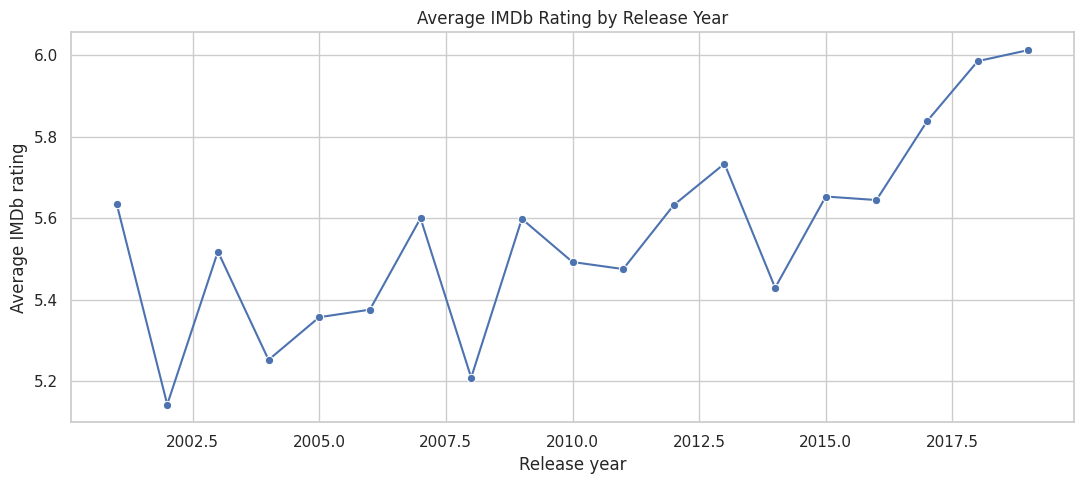

In [14]:
yearly = (clean.groupby("year_of_release")
          .agg(movie_count=("title_x", "count"),
               average_rating=("imdb_rating", "mean"),
               median_rating=("imdb_rating", "median"))
          .reset_index())
display(yearly.round(2))

plt.figure(figsize=(11, 5))
sns.lineplot(data=yearly, x="year_of_release", y="average_rating", marker="o")
plt.title("Average IMDb Rating by Release Year")
plt.xlabel("Release year")
plt.ylabel("Average IMDb rating")
plt.tight_layout()
plt.show()

### 7.4 IMDb votes and ratings

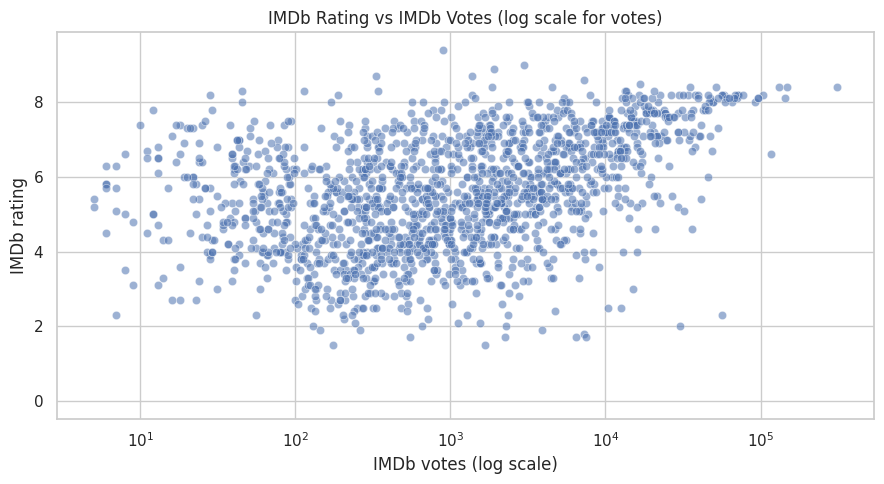

Correlation between IMDb rating and IMDb votes: 0.338


In [15]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=clean, x="imdb_votes", y="imdb_rating", alpha=0.55)
plt.xscale("log")
plt.title("IMDb Rating vs IMDb Votes (log scale for votes)")
plt.xlabel("IMDb votes (log scale)")
plt.ylabel("IMDb rating")
plt.tight_layout()
plt.show()

print("Correlation between IMDb rating and IMDb votes:",
      round(clean[["imdb_rating", "imdb_votes"]].corr().iloc[0, 1], 3))

## 8. Key findings (generated from the dataset)

In [16]:
print(f"Total movie records: {len(clean):,}")
print(f"Release-year range: {clean['year_of_release'].min()}–{clean['year_of_release'].max()}")
print(f"Average IMDb rating: {clean['imdb_rating'].mean():.2f}")
print(f"Median IMDb rating: {clean['imdb_rating'].median():.2f}")
print(f"Average runtime (available values): {clean['runtime_minutes'].mean():.1f} minutes")
print(f"Most frequent genre: {genre_counts.index[0]} ({genre_counts.iloc[0]} occurrences)")
print(f"Movies with missing tagline: {clean['tagline'].isna().sum()}")
print(f"Movies with missing awards information: {clean['wins_nominations'].isna().sum()}")

Total movie records: 1,629
Release-year range: 2001–2019
Average IMDb rating: 5.56
Median IMDb rating: 5.60
Average runtime (available values): 132.9 minutes
Most frequent genre: Drama (1085 occurrences)
Movies with missing tagline: 1072
Movies with missing awards information: 922


## 9. Conclusion

The supplied file contains movie records with release information, genres, IMDb ratings, vote counts, runtime, cast and descriptive metadata. Cleaning standardized text and missing-value markers, created a numeric runtime field, converted the adult flag to Boolean, and checked duplicates.

The charts and summary tables help compare release-year coverage, ratings, runtime, genres, audience vote counts, and year-level rating averages. Optional text fields such as taglines and awards contain many missing values, so they were retained rather than using aggressive row deletion.

## 10. Limitations
- IMDb ratings and vote counts are values present in this supplied snapshot; they may change over time.
- A rating threshold is used for the top-rated list to reduce small-sample bias, but it does not make the list universally definitive.
- Genre counts count each genre label in a movie's multi-genre field; one movie may contribute to several genres.
- Missing values are not necessarily errors: some metadata may not have been provided in the source.

## 11. Export cleaned dataset

In [17]:
clean.to_csv("movies_cleaned.csv", index=False)
print("Saved cleaned dataset as movies_cleaned.csv")

Saved cleaned dataset as movies_cleaned.csv
